In [26]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns

In [27]:
from pathlib import Path
path = Path.home() / "Desktop" / "genz_digital_lifestyle_tech_habits.csv"
df = pd.read_csv(path)
df.head()

,User_ID,Age,Gender,Daily_Screen_Time_hrs,Preferred_Device,Social_Media_Usage_hrs,Gaming_Activity,Tech_Savviness,Streaming_Subscriptions,Privacy_Awareness_Level
0,eedfaaf2,28,Male,11.4,Desktop,5.6,Occasional,Intermediate,1,Low
1,e9cbf4a6,19,Female,8.4,Tablet,3.2,Frequent,Intermediate,2,Medium
2,624e16c6,18,Female,9.5,Laptop,5.9,Never,Intermediate,2,Low
3,aace1ebf,29,Male,3.0,Tablet,3.2,Never,Intermediate,3,Low
4,3e967266,22,Female,2.1,Tablet,1.0,Frequent,Advanced,1,High


In [28]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 10 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   User_ID                  500 non-null    object 
 1   Age                      500 non-null    int64  
 2   Gender                   500 non-null    object 
 3   Daily_Screen_Time_hrs    500 non-null    float64
 4   Preferred_Device         500 non-null    object 
 5   Social_Media_Usage_hrs   500 non-null    float64
 6   Gaming_Activity          500 non-null    object 
 7   Tech_Savviness           500 non-null    object 
 8   Streaming_Subscriptions  500 non-null    int64  
 9   Privacy_Awareness_Level  500 non-null    object 
dtypes: float64(2), int64(2), object(6)
memory usage: 39.2+ KB


In [29]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, MinMaxScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split

In [30]:
#Define the order for the ranked categories
ord_mapping = [
    ["Never", "Occasional", "Frequent"],
    ["Beginner", "Intermediate", "Advanced", "Expert"],
    ["Low", "Medium", "High"]
]
# 1. Define Features (X) and Target (y)
X = df.drop(columns=["Preferred_Device","User_ID"])
y = df["Preferred_Device"]

#2.Build the pipeline (the flow chart) [Parallel: Handle different columns differently]
preprocessor = ColumnTransformer(
    transformers=[
        ("ord", OrdinalEncoder(categories=ord_mapping), ["Gaming_Activity", "Tech_Savviness", "Privacy_Awareness_Level"]),
        ("nom", OneHotEncoder(                     #keep distance symmetric
            handle_unknown="ignore",        #prevents crashes if new categories appear
            sparse_output=False             #useful for small datasets
        ), ["Gender"])
    ], 
    remainder="passthrough"     #Numerical columns pass through here
)
#3.Pipe the encoded data into a single scaler & Create the modeling pipeline
rf_pipeline = Pipeline(steps=[
    ("prep", preprocessor),     #First: Encoding
    ("scale", MinMaxScaler()),   #Second: Normalization
    ("model", RandomForestClassifier(
        n_estimators=100, 
        max_depth=5,            #don't let trees get too complex
        min_samples_leaf=15,    #ensure each 'group' has at least 15 people
        random_state=42
        ))                      #the default max_features is set to the square root of total vaariables
])

In [32]:
print(rf_pipeline.named_steps['model'].get_params())

{'bootstrap': True, 'ccp_alpha': 0.0, 'class_weight': None, 'criterion': 'gini', 'max_depth': 5, 'max_features': 'sqrt', 'max_leaf_nodes': None, 'max_samples': None, 'min_impurity_decrease': 0.0, 'min_samples_leaf': 15, 'min_samples_split': 2, 'min_weight_fraction_leaf': 0.0, 'monotonic_cst': None, 'n_estimators': 100, 'n_jobs': None, 'oob_score': False, 'random_state': 42, 'verbose': 0, 'warm_start': False}


In [33]:
from sklearn.model_selection import cross_val_score, train_test_split
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

In [34]:
#CROSS-VALIDATION (Check Reliability)
#do this before training on the full set to see if the model is stable
cv_scores = cross_val_score(rf_pipeline, X, y, cv=5)

print(f"--- Model Reliability ---")
print(f"Accuracy per fold: {cv_scores}")
print(f"Average Accuracy: {cv_scores.mean():.2f}")
print(f"Stability (std Dev): {cv_scores.std():.2f}")
print("-" * 25)

--- Model Reliability ---
Accuracy per fold: [0.22 0.24 0.15 0.22 0.27]
Average Accuracy: 0.22
Stability (std Dev): 0.04
-------------------------


In [35]:
print(df["Preferred_Device"].value_counts(normalize=True))

Preferred_Device
Tablet        0.224
Desktop       0.206
Smartphone    0.198
Smartwatch    0.194
Laptop        0.178
Name: proportion, dtype: float64


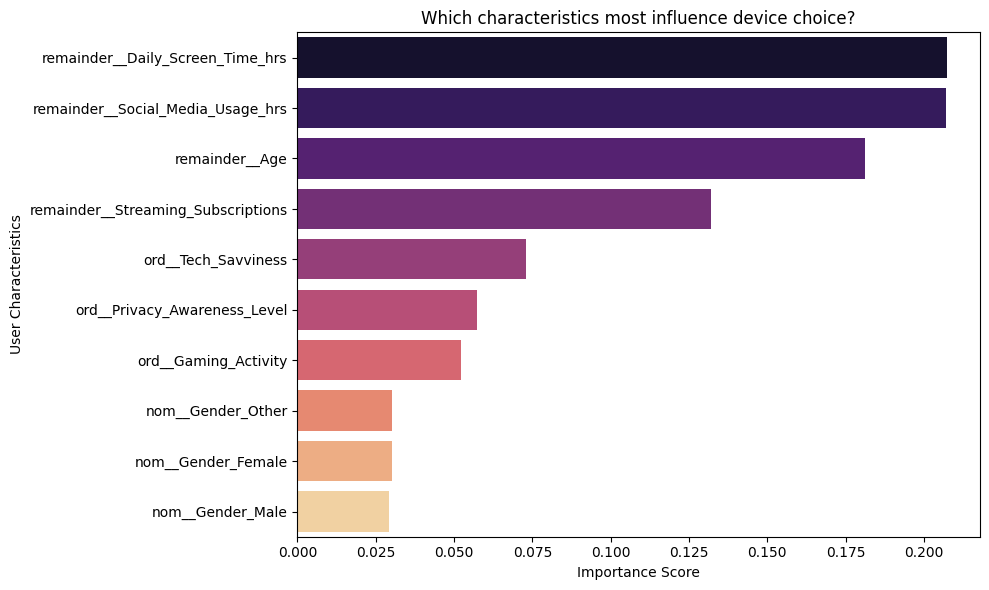

In [36]:
#Train & Identify Groups
#Train on all 500 rows to get the best possible 'Feature Importance'
rf_pipeline.fit(X, y)

#Extract feature names from the preprocessor and scores from the model 
feature_names= rf_pipeline.named_steps["prep"].get_feature_names_out()
importances = rf_pipeline.named_steps["model"].feature_importances_ #.f_m_scoring of model

#Create a summary DataFrame
importance_df = pd.DataFrame({"Feature": feature_names, "Importance": importances})
importance_df = importance_df.sort_values(by="Importance", ascending=False)

#PLOT THE RESULTS
plt.figure(figsize=(10, 6))
sns.barplot(data=importance_df, x="Importance", y="Feature", hue="Feature", palette="magma", legend=False)
plt.title("Which characteristics most influence device choice?")
plt.xlabel("Importance Score")
plt.ylabel("User Characteristics")
plt.tight_layout()
plt.show()

<Figure size 800x600 with 0 Axes>

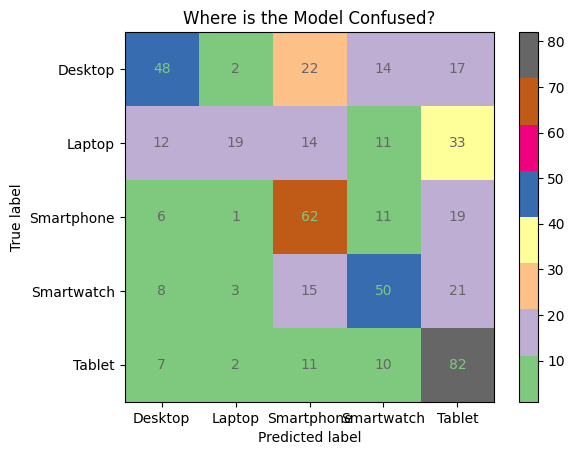

In [10]:
#CONFUSION MATRIX
#Get predictions
y_pred = rf_pipeline.predict(X)

#Plot the matrix
plt.figure(figsize=(8,6))
ConfusionMatrixDisplay.from_estimator(
    rf_pipeline, X, y,
    display_labels=rf_pipeline.classes_,
    cmap="Accent"
)
plt.title("Where is the Model Confused?")
plt.show()

In [38]:
# 1. Define the mapping
device_map = {
    'Desktop': 'Fixed',
    'Laptop': 'Large_Portable',
    'Tablet': 'Large_Portable',
    'Smartphone': 'Small_Portable',
    'Smartwatch': 'Small_Portable'
}

# 2. Apply it to create a new target
df['Device_Category'] = df['Preferred_Device'].map(device_map)

# 3. Update X and y
X_com = df.drop(columns=['Preferred_Device', 'Device_Category','User_ID'])
y_com = df['Device_Category']

# 4. Re-run your Pipeline and CV
# (Ensure class_weight='balanced' is still used just in case)
rf_pipeline.set_params(model__class_weight='balanced')
three_group_cv = cross_val_score(rf_pipeline, X_com, y_com, cv=5)

print(f"3-Group Average Accuracy: {three_group_cv.mean():.2f}")


3-Group Average Accuracy: 0.35


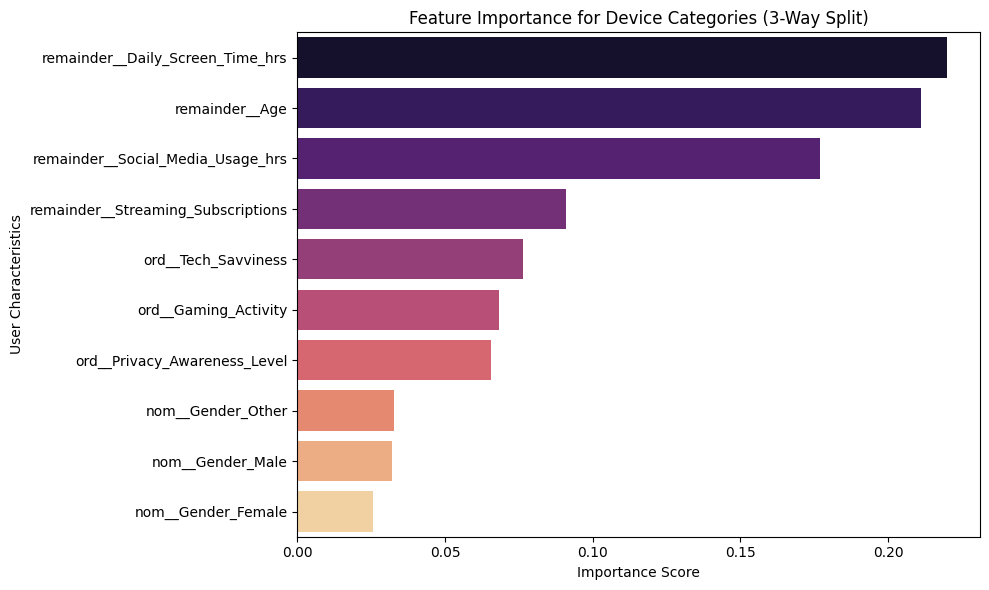

In [39]:
rf_pipeline.fit(X_com, y_com)

#Extract feature names from the preprocessor and scores from the model
feat_names= rf_pipeline.named_steps["prep"].get_feature_names_out()
importances = rf_pipeline.named_steps["model"].feature_importances_

#Create a summary DataFrame
importance_df = pd.DataFrame({"Feature": feat_names, "Importance": importances})
importance_df = importance_df.sort_values(by="Importance", ascending=False)

#PLOT THE RESULTS
plt.figure(figsize=(10, 6))
sns.barplot(data=importance_df, x="Importance", y="Feature", hue="Feature", palette="magma", legend=False)
plt.title("Feature Importance for Device Categories (3-Way Split)")
plt.xlabel("Importance Score")
plt.ylabel("User Characteristics")
plt.tight_layout()
plt.show()

In [40]:
# 1. SETUP DATA AND 3-CATEGORY TARGET
df_eng = df.copy()

device_map = {
    'Desktop': 'Fixed',
    'Laptop': 'Large_Portable', 'Tablet': 'Large_Portable',
    'Smartphone': 'Small_Portable', 'Smartwatch': 'Small_Portable'
}
df_eng['Device_Category'] = df_eng['Preferred_Device'].map(device_map)

# 2. FEATURE ENGINEERING (Manual Mapping + Interactions)
tech_map = {"Beginner": 1, "Intermediate": 2, "Advanced": 3, "Expert": 4}
game_map = {"Never": 0, "Occasional": 1, "Frequent": 2}

df_eng['Tech_Score'] = df_eng['Tech_Savviness'].map(tech_map)
df_eng['Game_Score'] = df_eng['Gaming_Activity'].map(game_map)

# Create "Intensity" features (combining knowledge/habit with screen time)
df_eng['Tech_Intensity'] = df_eng['Daily_Screen_Time_hrs'] * df_eng['Tech_Score']
df_eng['Gaming_Intensity'] = df_eng['Daily_Screen_Time_hrs'] * df_eng['Game_Score']

# 3. PREPARE X and y
# Dropping original columns that we manually mapped to avoid redundancy
X_int = df_eng.drop(columns=[
    'Preferred_Device', 'Device_Category', 
    'Tech_Savviness', 'Gaming_Activity', 'User_ID'
])
y_int = df_eng['Device_Category']

# 4. UPDATED PIPELINE
# Only 'Privacy_Awareness_Level' remains for the OrdinalEncoder
preprocessor = ColumnTransformer(
    transformers=[
        ("ord", OrdinalEncoder(categories=[["Low", "Medium", "High"]]), ["Privacy_Awareness_Level"]),
        ("nom", OneHotEncoder(handle_unknown="ignore", sparse_output=False), ["Gender"])
    ], 
    remainder="passthrough" # This picks up Daily_Screen_Time_hrs, Tech_Score, Game_Score, and Intensity features
)

rf_pipeline_int = Pipeline(steps=[
    ("prep", preprocessor),
    ("scale", MinMaxScaler()),
    ("model", RandomForestClassifier(
        n_estimators=100, 
        max_depth=5, 
        min_samples_leaf=15, 
        class_weight='balanced', 
        random_state=42
    ))
])

# 5. FINAL CROSS-VALIDATION
cv_results = cross_val_score(rf_pipeline_int, X_int, y_int, cv=5)

print(f"--- Final Test Results ---")
print(f"Average Accuracy with Interactions: {cv_results.mean():.2f}")
print(f"Standard Deviation: {cv_results.std():.2f}")


--- Final Test Results ---
Average Accuracy with Interactions: 0.36
Standard Deviation: 0.05


<Figure size 1000x800 with 0 Axes>

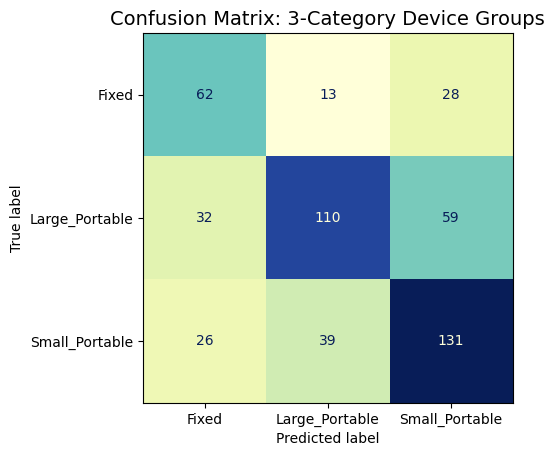

In [41]:
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# 1. Ensure the model is fitted on the latest 3-category data
rf_pipeline_int.fit(X_int, y_int)

# 2. Plot the Confusion Matrix
plt.figure(figsize=(10, 8))
cmd = ConfusionMatrixDisplay.from_estimator(
    rf_pipeline_int, 
    X_int, 
    y_int, 
    display_labels=rf_pipeline.classes_,
    cmap='YlGnBu', # A professional color scheme for presentations
    colorbar=False
)

plt.title("Confusion Matrix: 3-Category Device Groups", fontsize=14)
plt.grid(False) # Removes grid lines for a cleaner look
plt.show()


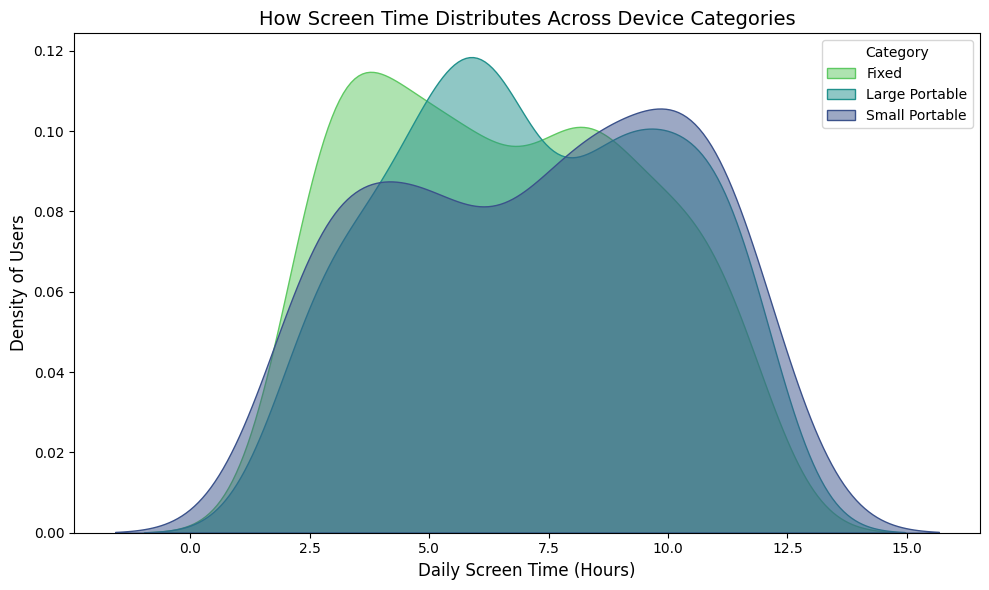

In [42]:
plt.figure(figsize=(10, 6))

# Creating the distribution plot
sns.kdeplot(data=df_eng, x='Daily_Screen_Time_hrs', hue='Device_Category', fill=True, common_norm=False, palette='viridis', alpha=0.5)

plt.title('How Screen Time Distributes Across Device Categories', fontsize=14)
plt.xlabel('Daily Screen Time (Hours)', fontsize=12)
plt.ylabel('Density of Users', fontsize=12)
plt.legend(title='Category', labels=['Fixed', 'Large Portable', 'Small Portable'])
plt.tight_layout()
plt.show()

In [43]:
from sklearn.tree import plot_tree

In [18]:
X_int.columns

Index(['Age', 'Gender', 'Daily_Screen_Time_hrs', 'Social_Media_Usage_hrs',
       'Streaming_Subscriptions', 'Privacy_Awareness_Level', 'Tech_Score',
       'Game_Score', 'Tech_Intensity', 'Gaming_Intensity'],
      dtype='object')

In [ ]:
#the pipeline acts as a translator. It takes 10 variables, expands them into 12 vars the model needs through 3 steps, 
# & ensures the accuracy stays exactly as it was during training.
#predictions = rf_pipeline_int.predict(X_int)

In [ ]:
#'model' is causing error in the plotting code. It took Gender as 3 cols instead of 1 col.
#the 'model' step only knows how to handle the 12-column output produced by the 'prep' and 'scale' step.
#In scikit-learn, the plot_tree func requires the 'feature_names' list to exactly match the no of features the model actually sees (the 'transformed' data)
#so, must use the feature names generated by the 'preprocessor' to fox the plotting code error
#in 'prep' stage, it starts to transforms 10 cols into 12. so, the 'model'only accepts 12 items

In [44]:
#1. Check how many features the model actually expects
model = rf_pipeline_int.named_steps["model"]
expected_features = model.n_features_in_
print(f"Model expects {expected_features} features.")
print(f"Your 'feat_names' has {len(feat_names)} items.")

#2. Check the classes (for classifiers)
if hasattr(rf_pipeline_int, "classes_"):
    print(f"Model has {len(rf_pipeline_int.classes_)} classes: {rf_pipeline_int.classes_}")

Model expects 12 features.
Your 'feat_names' has 10 items.
Model has 3 classes: ['Fixed' 'Large_Portable' 'Small_Portable']


In [45]:
# If your model was trained on a DataFrame, it usually stores feature names
try:
    expected_names = rf_pipeline_int.named_steps["model"].feature_names_in_
    missing = set(expected_names) - set(feat_names)
    print(f"Missing features: {missing}")
except AttributeError:
    print("Model doesn't have feature_names_in_. Check your training data columns.")


Model doesn't have feature_names_in_. Check your training data columns.


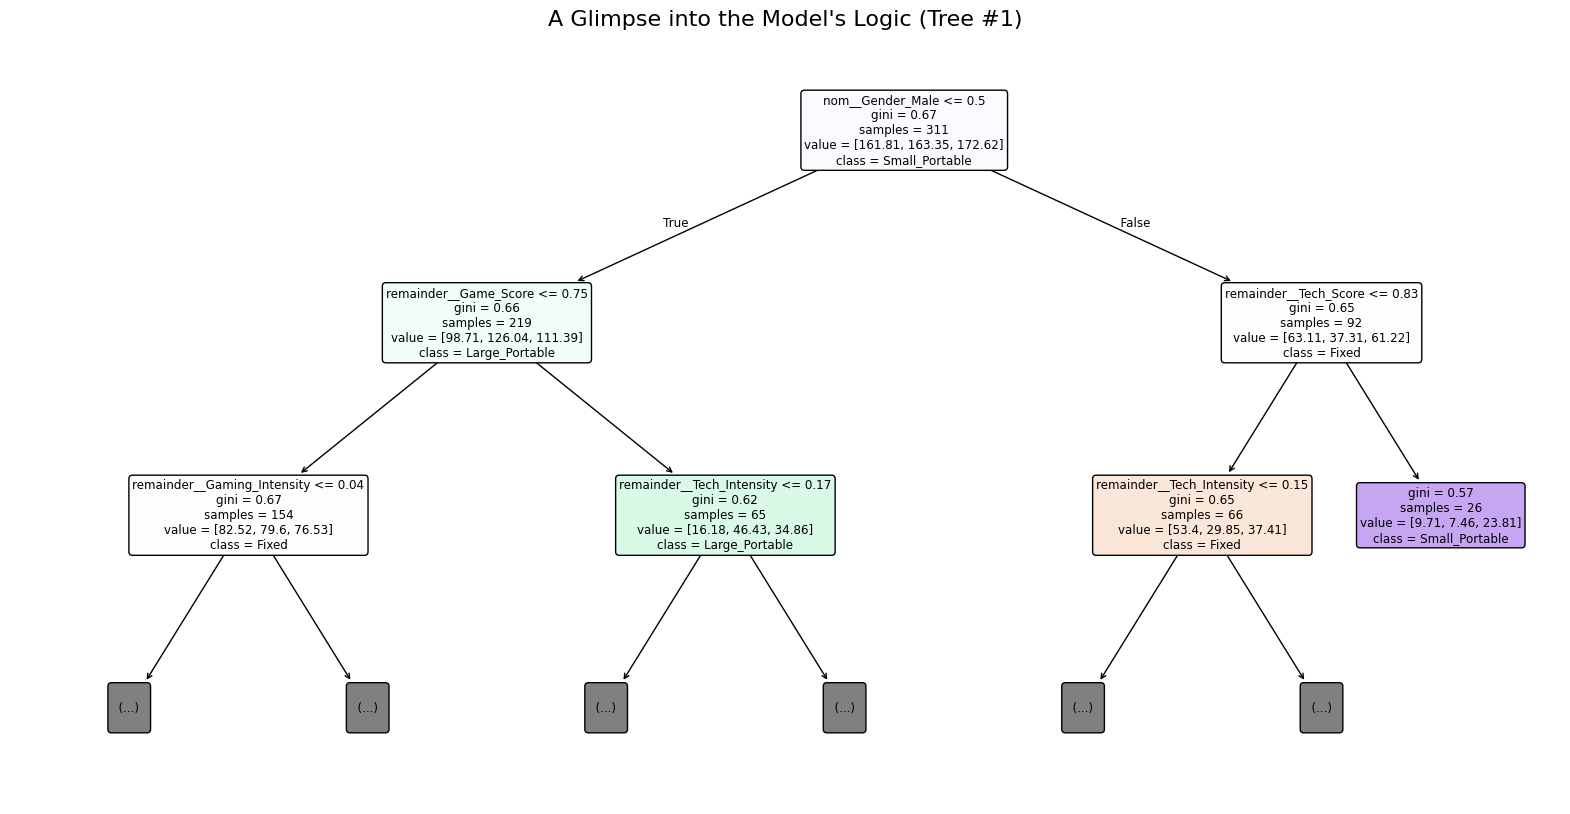

In [50]:
from sklearn.tree import plot_tree

# 1. Access the FIRST tree in the forest (index 0)
single_tree = rf_pipeline_int.named_steps['model'].estimators_[0]

#Get the actual 12 feature names from the preprocessing step
transformed_names = rf_pipeline_int.named_steps['prep'].get_feature_names_out()

# 2. Plot the tree
plt.figure(figsize=(20, 10))
plot_tree(
    single_tree,
    feature_names=list(transformed_names), # Use the 12 transformed names
    class_names=rf_pipeline_int.classes_,
    max_depth=2,      # Keeps it readable for your presentation
    filled=True,      # Colors nodes by their majority class
    rounded=True, 
    precision=2       # Limits decimals to 2
)

plt.title("A Glimpse into the Model's Logic (Tree #1)", fontsize=16)
plt.show()


In [36]:
print(len(feat_names))
print(rf_pipeline.named_steps['model'].n_features_in_)

10
10


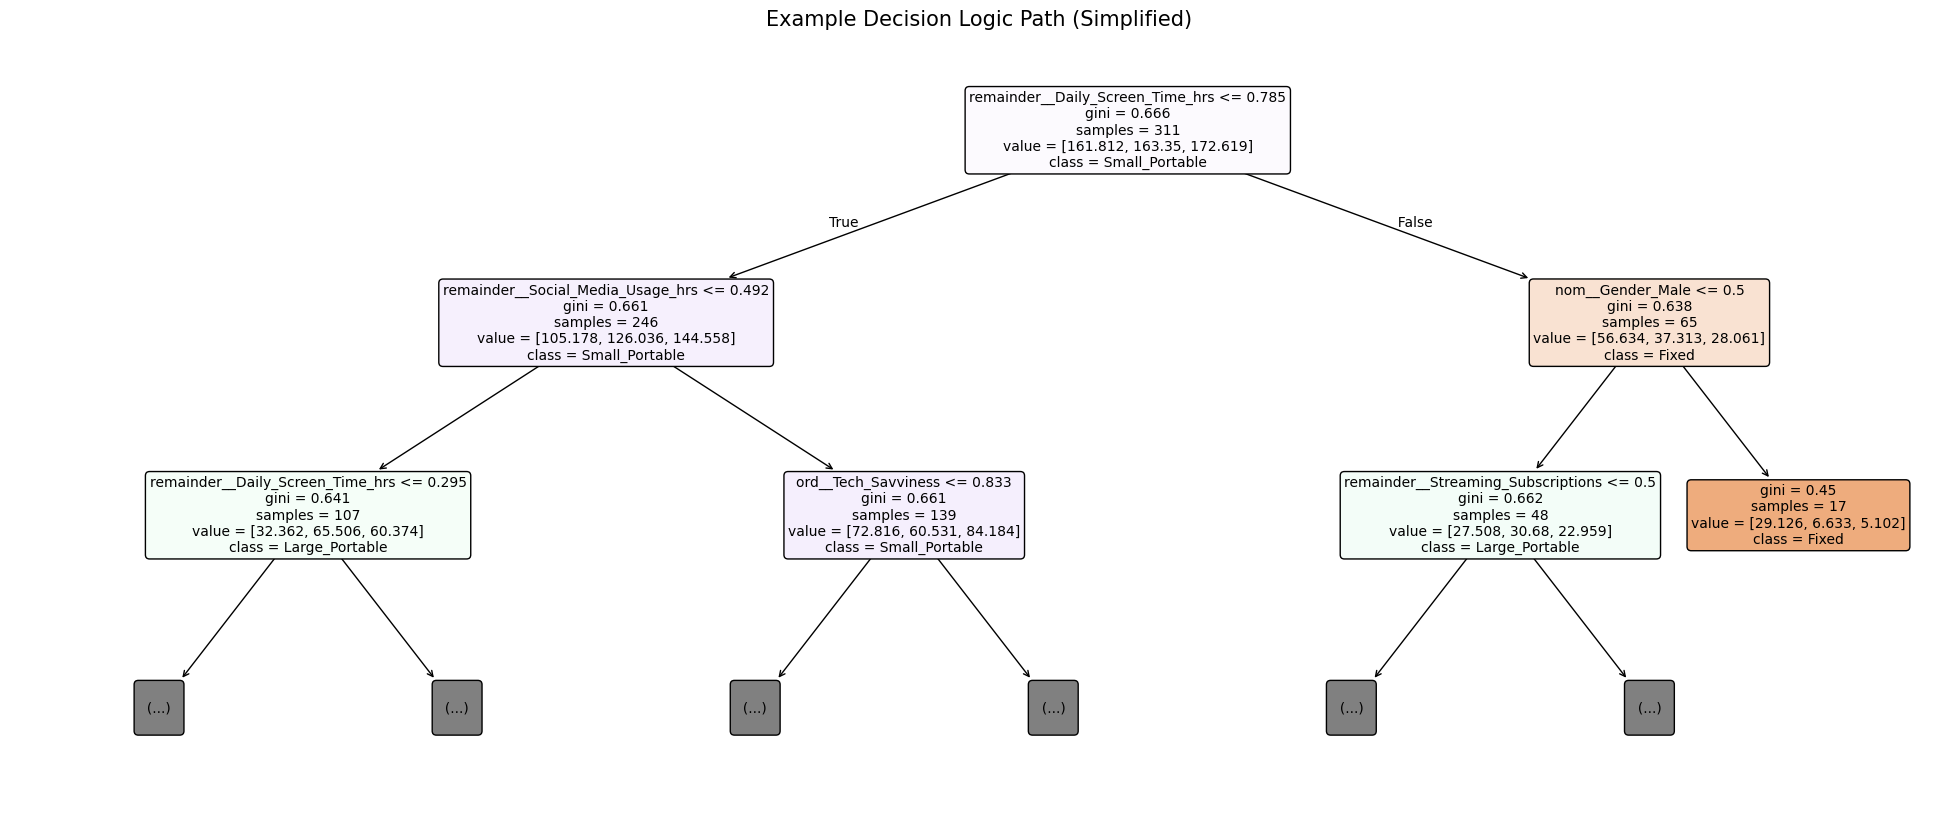

In [51]:
#transformed_names = rf_pipeline_int.named_steps['prep'].get_feature_names_out()

# Extracting one individual tree (tree #0) from the forest
plt.figure(figsize=(25, 10))
plot_tree(
    rf_pipeline.named_steps['model'].estimators_[0],
    feature_names=feat_names,
    class_names=rf_pipeline.classes_,
    max_depth=2, # Limiting depth so it's readable
    filled=True,
    rounded=True,
    fontsize=10
)
plt.title("Example Decision Logic Path (Simplified)", fontsize=15)
plt.show()

In [52]:
X_int.columns

Index(['Age', 'Gender', 'Daily_Screen_Time_hrs', 'Social_Media_Usage_hrs',
       'Streaming_Subscriptions', 'Privacy_Awareness_Level', 'Tech_Score',
       'Game_Score', 'Tech_Intensity', 'Gaming_Intensity'],
      dtype='object')